# PHYG 2026 — TME 1
### Phylogénie et génomique comparative
## Distance-based phylogeny: UPGMA and Neighbor-Joining

| | |
|---|---|
| **Student 1** | _surname, first name_ |
| **Student 2** | _surname, first name_ |
| **Date** | _dd/mm/yyyy_ |

Léon Faure — <leon.faure@sorbonne-universite.fr>
Course materials: <https://github.com/leonfaure/PHYG2026>

> ### Overview
>
> In this session, you will build distance-based trees (UPGMA and Neighbor-Joining), first by
> hand and then on real protein families, and asks what those trees do — and do
> not — tell you about evolution.
>
> **Learning items**:
> - explain the fundamental concepts and assumptions underlying molecular phylogenetics;
> - understand the mathematical foundations of phylogenetic reconstruction;
> - compare major phylogenetic reconstruction methods (here: distance-based);
> - interpret phylogenetic trees in biological and evolutionary contexts.

> ### About these sessions
>
> The TMEs account for only **10% of the final grade**. They are there to help you
> understand the course material and to get hands-on experience with real
> problems — not to produce a perfect report. Please do the thinking yourself: it
> is **discouraged to let an AI do the work for you**. Using one to help you
> *understand* a concept, a tool or an error message is fine; handing it the
> questions and pasting back the answers defeats the purpose.

---

### How to hand this in

**Deadline: 19 November.** Work in groups of **at most two students**; you may
also work alone.

1. Fill in your names in the table above.
2. Answer **every** question — in the `Your answer` markdown cells for written
   answers, in the `TODO` code cells for code. Where a question only asks you to
   display something, the figure itself is the answer.
3. **Restart the kernel and run all cells** (`Kernel → Restart Kernel and Run All Cells`)
   and check it runs top to bottom without errors.
4. Rename the file `SURNAME1_SURNAME2_TME1.ipynb` and e-mail it to
   <leon.faure@sorbonne-universite.fr> with the subject `[PHYG] TME1`.

Send **the notebook only** — no PDF, no archive. Figures produced by your code
are stored inside the `.ipynb` as cell outputs, so they travel with it.
The pictures that come with the instructions (such as the animations in
Exercise 5) stay in the repository: do not send them.

***
## Toolbox

**Run the cell below first.** It is provided — you do not need to modify it, but
do read the function signatures, you will be using them throughout the notebook.

`align_sequences()`, `distance_matrix()` and `build_tree()` are thin wrappers
around **Clustal Omega**, **`protdist`** and **`neighbor`** — the programs the
handout asks you to use. They run the real thing; they just spare you the
menu-driven interface and the `infile`/`outfile` shuffling.

> **If something looks wrong**
> - *A cell shows `[*]` for several seconds.* It has not frozen: `protdist` takes
>   about 3 s on P53, 7 s on CFTR and 8 s on the spike protein.
> - *`NameError: name '...' is not defined`.* The Toolbox cell has not run in the
>   current kernel (restarting the kernel forgets everything). Use
>   `Kernel → Restart Kernel and Run All Cells`, and keep any cell you add
>   *below* the Toolbox.

### Including a photo or a screenshot

For a photograph of something worked out on paper, put the file next to this
notebook and call `embed_image()` in a code cell:

```python
embed_image("my_upgma_tree.jpg", caption="Exercise 1 — UPGMA by hand")
```

It stores the image **inside** the notebook's output, so it survives being
e-mailed. Writing `![](my_tree.jpg)` in markdown, or dragging a file into
JupyterLab, does **not** work: only a *path* is kept and the image stays on your
machine.

In [ ]:
import io, re, subprocess, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio import SeqIO, AlignIO, Phylo
from Bio.Phylo.TreeConstruction import DistanceMatrix
from IPython.display import Image as _Image, display

plt.rcParams["figure.dpi"] = 110


# --------------------------------------------------------------------------
# PHYLIP plumbing. You do not need to read this part.
#
# Two things have to be worked around. PHYLIP identifies sequences by exactly
# ten characters, which collides badly on this course's data — the 55 spike
# sequences collapse to 27 distinct names, and CFTR loses one of the two
# muntjacs. So we hand PHYLIP unique tokens and put the real names back
# afterwards. And PHYLIP reads and writes fixed filenames in the current
# directory, refusing to start if `outfile` is already there, so every run gets
# a private temporary directory.
# --------------------------------------------------------------------------

def _tokens(names):
    return {name: "SEQ%07d" % i for i, name in enumerate(names)}


def _run_phylip(program, infile_text, keystrokes):
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        (tmp / "infile").write_text(infile_text)
        proc = subprocess.run([program], input=keystrokes, cwd=tmp,
                              text=True, capture_output=True, timeout=3600)
        outfile, outtree = tmp / "outfile", tmp / "outtree"
        if not outfile.exists():
            raise RuntimeError("%s did not produce an outfile.\n\n%s"
                               % (program, (proc.stdout or proc.stderr)[-2000:]))
        return outfile.read_text(), (outtree.read_text() if outtree.exists() else None)


def _wrap(prefix, values, per_line=6):
    out, chunk = [], [values[i:i + per_line] for i in range(0, len(values), per_line)]
    for i, part in enumerate(chunk):
        head = prefix if i == 0 else " " * len(prefix)
        out.append(head + "".join("%12.6f" % v for v in part))
    return out


# --------------------------------------------------------------------------
# Alignments
# --------------------------------------------------------------------------

def read_alignment(path):
    """Read an *already aligned* FASTA file."""
    return AlignIO.read(path, "fasta")


def align_sequences(path, rename=None):
    """Align unaligned sequences with Clustal Omega.

    `rename` is an optional function applied to each sequence description.
    """
    records = list(SeqIO.parse(path, "fasta"))
    for rec in records:
        if rename:
            rec.id = rename(rec.description)
        rec.name, rec.description = rec.id, ""
    with tempfile.TemporaryDirectory() as tmp:
        src, dst = Path(tmp) / "in.fasta", Path(tmp) / "out.fasta"
        SeqIO.write(records, src, "fasta")
        subprocess.run(["clustalo", "-i", str(src), "-o", str(dst),
                        "--outfmt=fasta", "--force"],
                       check=True, capture_output=True, text=True, timeout=3600)
        return AlignIO.read(dst, "fasta")


def uniprot_species(description):
    """'sp|P00439|PH4H_HUMAN ... OS=Homo sapiens GN=PAH ...' -> 'Homo_sapiens'."""
    m = re.search(r"OS=(.+?)\s+(?:OX=|GN=|PE=|SV=)", description)
    return m.group(1).replace(" ", "_") if m else description.split()[0]


# --------------------------------------------------------------------------
# Distances and trees — PHYLIP `protdist` and `neighbor`
# --------------------------------------------------------------------------

def distance_matrix(alignment):
    """Pairwise distances with PHYLIP's `protdist` (Dayhoff PAM model)."""
    names = [rec.id for rec in alignment]
    tok = _tokens(names)
    text = [" %d %d" % (len(names), alignment.get_alignment_length())]
    text += ["%s%s" % (tok[rec.id], str(rec.seq).upper()) for rec in alignment]

    outfile, _ = _run_phylip("protdist", "\n".join(text) + "\n", "Y\n")

    back = {v: k for k, v in tok.items()}
    fields = outfile.split()
    n, pos = int(fields[0]), 1
    order, rows = [], []
    for _ in range(n):
        order.append(back[fields[pos]]); pos += 1
        rows.append([float(x) for x in fields[pos:pos + n]]); pos += n
    where = {name: i for i, name in enumerate(order)}
    square = [[rows[where[a]][where[b]] for b in names] for a in names]
    return DistanceMatrix(names=list(names),
                          matrix=[[square[i][j] for j in range(i + 1)]
                                  for i in range(len(names))])


def build_tree(dm, method="nj"):
    """Build a tree from a distance matrix with PHYLIP's `neighbor`.
    method: 'nj' (Neighbor-Joining) or 'upgma'.
    """
    names = list(dm.names)
    tok = _tokens(names)
    back = {v: k for k, v in tok.items()}
    text = ["   %d" % len(names)]
    for i, name in enumerate(names):
        text += _wrap(tok[name], [dm[i, j] for j in range(len(names))])

    keystrokes = "Y\n" if method == "nj" else "N\nY\n"
    _, outtree = _run_phylip("neighbor", "\n".join(text) + "\n", keystrokes)
    if outtree is None:
        raise RuntimeError("neighbor produced no tree")

    tree = Phylo.read(io.StringIO(outtree.replace("\n", "")), "newick")
    for tip in tree.get_terminals():
        tip.name = back.get((tip.name or "").strip(), tip.name)
    if method == "nj":
        tree.root_at_midpoint()     # NJ is unrooted; midpoint is only for drawing
    return tree


def negative_branches(tree):
    """List the negative branch lengths in a tree, most negative first."""
    out = [(c.name or "(internal)", c.branch_length)
           for c in tree.find_clades()
           if c.branch_length is not None and c.branch_length < 0]
    return sorted(out, key=lambda x: x[1])


def sister_group(tree, taxa):
    """Smallest clade of `tree` containing at least two of `taxa`.

    Returns (which of `taxa` are in it, all its leaves). You may use it to answer
    'which of these species group together?' without searching on the figure,
    and read the *topology* like this rather than comparing tree.distance()
    values, which negative branch lengths distort.
    """
    taxa = set(taxa)
    best = None
    for clade in tree.find_clades():
        leaves = {t.name for t in clade.get_terminals()}
        if len(leaves & taxa) >= 2 and (best is None or len(leaves) < len(best)):
            best = leaves
    if best is None:
        return None, None
    return sorted(best & taxa), sorted(best)


def save_newick(tree, path):
    """Write the tree in Newick format (e.g. to upload it to iTOL)."""
    Phylo.write(tree, path, "newick")
    print("wrote", path)


# --------------------------------------------------------------------------
# Display
# --------------------------------------------------------------------------

def as_dataframe(dm, decimals=3):
    """Distance matrix as a pandas table, so it displays nicely in the notebook."""
    n = len(dm.names)
    full = [[dm[i, j] for j in range(n)] for i in range(n)]
    return pd.DataFrame(full, index=dm.names, columns=dm.names).round(decimals)


def show_tree(tree, title="", highlight=(), figsize=None):
    """Draw a tree inline. Names in `highlight` are coloured red."""
    n = len(tree.get_terminals())
    fig, ax = plt.subplots(figsize=figsize or (9, max(2.5, 0.22 * n + 1)))
    hl = set(highlight)
    Phylo.draw(tree, axes=ax, do_show=False,
               label_colors=lambda name: "crimson" if name in hl else "black")
    ax.set_title(title)
    ax.set_ylabel("")
    ax.set_yticks([])
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    plt.show()
    neg = negative_branches(tree)
    if neg:
        print("note: %d branch(es) have a negative length (most negative: %.4f). "
              "This is normal for NJ — see the note below." % (len(neg), neg[0][1]))


def embed_image(path, max_width=1000, caption=""):
    """Put an image file *inside* the notebook, so it travels with the .ipynb.

    Use this for photographs of work done on paper, and for screenshots.
    The image is downscaled and stored in this cell's output — once it has run,
    the original file is no longer needed by anyone reading your notebook.
    """
    from PIL import Image as _PIL
    im = _PIL.open(path)
    if im.width > max_width:
        im = im.resize((max_width, round(im.height * max_width / im.width)),
                       _PIL.LANCZOS)
    buf = io.BytesIO()
    if im.mode in ("RGBA", "LA", "P"):
        im.convert("RGBA").save(buf, format="PNG", optimize=True)
    else:
        im.convert("RGB").save(buf, format="JPEG", quality=85, optimize=True)
    display(_Image(data=buf.getvalue()))
    print("%s  (%dx%d, %.0f KB embedded in this notebook)"
          % (caption or path, im.width, im.height, len(buf.getvalue()) / 1024))


print("Toolbox loaded.")

***
## From the lecture

Definitions and formulas the questions below assume. None of this is an answer.

**Additional help — two short videos** walking through the algorithms step by step
(Prof. Greg Tucker-Kellogg):
[UPGMA](https://youtu.be/061ukTACDvY) and
[Neighbor-Joining](https://youtu.be/7tn90VWGmV4).
Useful before you start Exercise 1.

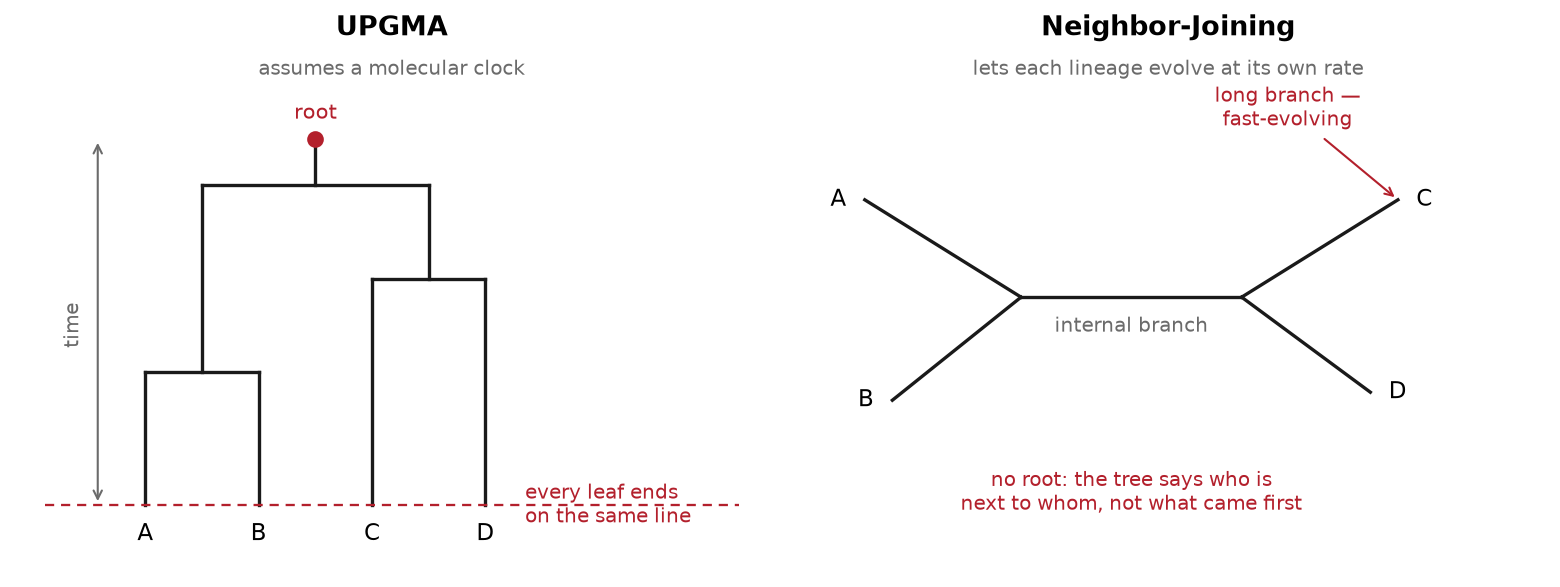

**Ultrametric** — for every triple $i, j, k$, the two largest of
$d_{ij}, d_{ik}, d_{jk}$ are equal. Equivalently: every leaf sits at the same
distance from the root, i.e. a molecular clock holds. This is what UPGMA assumes.

**Additive** — for every quartet $i, j, k, l$, the two largest of
$d_{ij} + d_{kl}$, $\;d_{ik} + d_{jl}$, $\;d_{il} + d_{jk}$ are equal
(the *four-point condition*). Equivalently: every distance is exactly the sum of
the branch lengths on the path between the two leaves. This is what NJ needs, and
it is the weaker condition — every ultrametric matrix is additive, not the reverse.

**UPGMA** joins the **closest** pair, puts the new node at height $d_{ij}/2$, and
replaces the pair by a cluster whose distance to anything else is the size-weighted
average

$$d(C_{ij},\,k) \;=\; \frac{|i|\,d_{ik} + |j|\,d_{jk}}{|i| + |j|}$$

**Neighbor-Joining** joins the pair minimising

$$Q_{ij} \;=\; (n-2)\,d_{ij} - r_i - r_j, \qquad r_i = \sum_k d_{ik}$$

— which is *not* generally the closest pair. Branch lengths to the new node $u$ are

$$\delta(i,u) = \frac{d_{ij}}{2} + \frac{r_i - r_j}{2(n-2)},
\qquad d(u,k) = \frac{d_{ik} + d_{jk} - d_{ij}}{2}$$

**Practical notes for the by-hand runs**

- *NJ, every step:* after each join, recompute the row sums $r_i$ and $Q$ on the
  new, smaller matrix — $n$ and every $r_i$ have changed. When **3 nodes** remain,
  stop computing $Q$ (only one topology is possible) and place the last internal node with

$$\delta(i,c) = \frac{d_{ij} + d_{ik} - d_{jk}}{2}$$

- *Ties:* if several pairs share the minimum ($d$ for UPGMA, $Q$ for NJ), pick any
  one and say which. Disjoint pairs give the same tree whichever you take.
- *Drawing:* an NJ tree is **unrooted** — do not add a root, and draw branch lengths
  to scale. Only UPGMA gives a rooted tree with all leaves at the same height.
- *Self-check:* in an additive tree, each leaf-to-leaf distance equals the sum of the
  branch lengths along the path between them.

***
# Exercise 1 — UPGMA and Neighbor-Joining by hand

Take the distance matrix below and construct trees using **both** NJ and UPGMA.
For each algorithm, write one line per step (which pair is joined, the new
distances) and draw the resulting tree.

|        | **S1** | **S2** | **S3** | **S4** |
|--------|:------:|:------:|:------:|:------:|
| **S1** |    0   |    6   |    7   |    5   |
| **S2** |    6   |    0   |   11   |    9   |
| **S3** |    7   |   11   |    0   |    6   |
| **S4** |    5   |    9   |    6   |    0   |

Then answer:

1. Which of the two trees is more reliable? Why?
2. Is this matrix **ultrametric**?
3. Is this matrix **additive**?

> Do this one **on paper** — the point is the algorithm, not the output. Photograph
> your work, then embed the photo with `embed_image()` in the code cell below.
> Use the last code cell of this exercise only to *check* the answer you obtained
> by hand.

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

In [ ]:
# ---- TODO 1/2 : the hand-drawn trees ----
# Embed the photograph of your hand-drawn trees here, e.g.
# embed_image("ex1_by_hand.jpg", caption="Exercise 1 — UPGMA and NJ by hand")

In [ ]:
# The matrix above, ready to use.
from Bio.Phylo.TreeConstruction import DistanceMatrix

dm_ex1 = DistanceMatrix(
    names=["S1", "S2", "S3", "S4"],
    matrix=[[0],
            [6, 0],
            [7, 11, 0],
            [5, 9, 6, 0]],
)
as_dataframe(dm_ex1, decimals=0)

In [ ]:
# ---- TODO 2/2 : check your hand-made trees ----
# Build the UPGMA and the NJ tree from dm_ex1 and display both, so you can
# compare them with the trees you drew by hand.
# build_tree(dm, "upgma") and build_tree(dm, "nj") both run PHYLIP's `neighbor`;
# the matrix is not consumed, so you can build both from the same dm_ex1.

***
# Exercise 2 — Phenylalanine-4-hydroxylase (PAH)

Phenylalanine-4-hydroxylase degrades phenylalanine. In humans a mutation in its
gene causes **phenylketonuria**.

The file `sequences/PH4H_sequences.fasta` holds the *unaligned* PAH sequences of
human, rat (*Rattus norvegicus*), mouse (*Mus musculus*), bovine (*Bos taurus*)
and *Caenorhabditis elegans*, downloaded from
[UniProt](https://www.uniprot.org) (search `phenylalanine-4-hydroxylase`).

In [ ]:
# The sequences are not aligned yet — look at their lengths.
for record in SeqIO.parse("sequences/PH4H_sequences.fasta", "fasta"):
    print("%-6d %s" % (len(record.seq), record.description[:70]))

In [ ]:
# ---- TODO ----
# 1. Align the sequences with align_sequences().
#    Pass rename=uniprot_species so the leaves are named 'Homo_sapiens' etc.
#    rather than 'sp|P00439|PH4H_HUMAN'.
# 2. Print the number of sequences and the alignment length.
# Expected: 5 sequences, alignment length 462.

pah_aln = ...

**Q2.1** Compute the distance matrix for these sequences and include it in your
answer. `distance_matrix()` runs PHYLIP's `protdist` for you — it writes the
alignment out, runs the program and reads its matrix back, so these are exactly
the numbers `protdist` would give you at the command line. It takes a few
seconds on the bigger alignments.

In [ ]:
# ---- TODO ----
# Compute the distance matrix and display it with as_dataframe().

pah_dm = ...

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

**Q2.2** Compute **both** an UPGMA tree and a Neighbor-Joining tree, and display them.

_Your answer is the figure produced by the cell below._

> **Optional — an interactive tree.** `show_tree()` draws a static figure, which is
> what your answer should contain. If you would rather explore a tree — collapse
> clades, re-root it, colour labels — save it with `save_newick(tree, "mytree.nwk")`
> and upload the file to [iTOL](https://itol.embl.de/upload.cgi). Handy for the
> larger trees of Exercises 3 to 5; it is not required.

In [ ]:
# ---- TODO ----
# Build and show both trees. Give each show_tree() call a title so the two
# figures can be told apart in your report.

> ### A note on negative branch lengths
>
> Some of your NJ trees will contain **negative branch lengths**, drawn as short
> segments pointing backwards. This is not a bug and you do not need to fix it.
> NJ solves for branch lengths from the distance matrix, and an all-positive
> solution exists only if the matrix is perfectly **additive**. Real distances
> never are (estimation noise, saturation), so a very short internal branch can
> come out slightly below zero. Read a negative branch as "this branch is
> essentially zero": the true length is tiny, and the noise in the distances is
> larger than the branch itself, so the method overshoots below zero. Most are
> tiny; a clearly negative one flags a leaf that fits the tree poorly. UPGMA never produces them
> because it assigns heights rather than solving for lengths — that makes it
> neater, not more trustworthy.
>
> **Consequence:** negative branches distort `tree.distance(a, b)`. Compare species
> by reading the **topology**, never those numbers.
>
> `negative_branches(tree)` lists them; `build_tree(..., clamp_negative=True)` sets
> them to zero for a tidier figure.

In [ ]:
# ---- TODO ----
# Check whether your PAH NJ tree contains negative branches.
# negative_branches(...) returns a list of (name, length) pairs.

**Q2.3** Neighbor-Joining returns an **unrooted** tree. Given that, are the two
trees really different? Justify your answer.

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

***
# Exercise 3 — CFTR

The *cystic fibrosis transmembrane conductance regulator* (CFTR) regulates the
movement of chloride and sodium ions across epithelial cell membranes. A mutation
in this protein causes cystic fibrosis (*mucoviscidose*).

`sequences/CFTR_in_mammals.fasta` is an alignment of CFTR proteins across 45 mammals.

In [ ]:
# ---- TODO ----
# Read the alignment (it is already aligned — use read_alignment, not
# align_sequences), compute the distance matrix, and display the matrix.
# Expected: 45 sequences, alignment length 1495. `protdist` takes about 7 s.

cftr_aln = ...
cftr_dm = ...

**Q3.1** Compute both the UPGMA and the NJ tree and display them.

_Your answer is the figure produced by the cell below._

In [ ]:
# ---- TODO ----
# Build and display both trees from cftr_dm — `protdist` is slow, so compute the
# matrix once (above) and reuse it. 45 leaves is a lot: pass a taller figsize,
# e.g. figsize=(9, 11), so the labels stay readable.

**Q3.2** Look at **rat** (`Rattus_norvegicus`) and **mouse** (`Mus_musculus`).
What do you observe with UPGMA? And with NJ? Now look at these two species in the
distance matrix — what do you notice, and how does it explain what the two
methods did?

In [ ]:
# ---- TODO ----
# Pull the rat and mouse rows out of the distance matrix to support your answer.
# Compare their mean distance to the other species with the overall mean.
# Hint: as_dataframe(cftr_dm).loc[["Rattus_norvegicus", "Mus_musculus"]]

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

**Q3.3** Now look at the **pig** (*Sus scrofa*) and its position relative to the
**bovine** (*Bos taurus*) and the **horse** (*Equus caballus*). The accepted tree
of placental mammals is shown below.

Is the pig closer to the bovine or to the horse? What did UPGMA find? What did
NJ find? Which of the two got it right?

> Redraw both trees with `show_tree(tree, highlight=targets)` so the three species
> stand out, and use `sister_group()` to check which two end up together.

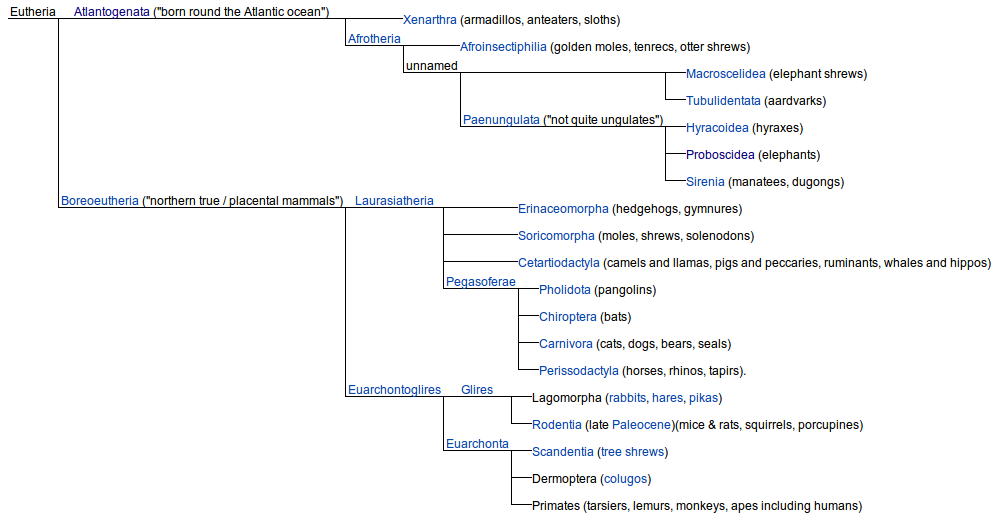

In [ ]:
# ---- TODO ----
# Use sister_group() on each of your two trees to answer this without having to
# squint at the figures.

targets = ["Sus_scrofa", "Bos_taurus", "Equus_caballus"]

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

***
# Exercise 4 — P53

The tumour suppressor P53 regulates apoptosis and cell growth: it protects
against cancer by preventing a cell from forming a tumour. When its gene is
mutated in somatic cells the protein stops working and the cell can generate a
tumour — which is why sequencing tumour cells so often reveals mutations here.

`sequences/p53.fasta` is an alignment of P53 across 72 species.

In [ ]:
# ---- TODO ----
# Read the P53 alignment, compute its distance matrix, build the NJ tree and
# display it (figsize=(9, 16) works well for 72 leaves).
# Expected: 72 sequences, alignment length 442.

p53_aln = ...

**Q4.1** Compare the position of these four species in the **CFTR** NJ tree and
in the **P53** NJ tree:

*Homo sapiens*, *Felis catus* (cat), *Loxodonta africana* (elephant),
*Monodelphis domestica* (opossum).

Which species group together in which tree?

In [ ]:
# ---- TODO ----
# Use sister_group() on both trees with the four species below, and pass
# highlight=four to show_tree() so they are easy to spot in the figures.

four = ["Homo_sapiens", "Felis_catus", "Loxodonta_africana", "Monodelphis_domestica"]

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

**Q4.2** Using your answer to Q4.1: the opossum is a **marsupial**, so it falls
outside the placental tree shown in Exercise 3 — it should be the outgroup of the
other three.

Is the CFTR NJ tree correct on this point? Is the P53 tree? What does that tell
you about using a single gene to reconstruct a species tree?

### &#9997;&#65039; Your answer

_Double-click this cell and replace this line with your answer._

***
# Exercise 5 — Coronaviridae

Coronaviridae are enveloped viruses that rely on membrane fusion with the host
cell to enter it and begin using its machinery to translate the viral RNA. They
are named after the spike protein decorating the virion surface like a crown
(*corona*). The family has four lineages — $\alpha$, $\beta$, $\gamma$, $\delta$
— which have nothing to do with the SARS-CoV-2 variants. Human-infecting members
(including one common cold virus) belong to $\alpha$- and $\beta$-Coronaviridae;
SARS-CoV, SARS-CoV-2 and MERS are all $\beta$-Coronaviridae.

Q5.1 to Q5.4 are answered from the **references at the end of the notebook**.

![The SARS-CoV-2 virion](d41586-021-02039-y_19383024.gif)

*The SARS-CoV-2 virion; the spike proteins are the green crown. Animation from
reference 5 (Nature).*

**Q5.1** What are the four structural proteins composing the SARS-CoV-2 virion?

**Q5.2** What are the two major parts of the viral spike (S) protein?

**Q5.3** Briefly explain the membrane fusion process. What is the role of the
spike protein?

![Spike-mediated membrane fusion](d41586-021-02039-y_19383078.gif)

*Spike proteins bridging the virus and the host cell membrane. Animation from
reference 5 (Nature).*

**Q5.4** What are the two largest domains of the S1 fragment of the spike protein?
Explain their roles.

### &#9997;&#65039; Your answer — Q5.1 to Q5.4

_Double-click this cell and replace this line with your answer._

**Q5.5** `sequences/S_protein.fasta` is an alignment of the spike protein across 55
coronaviruses. Reconstruct and display the tree.

_Your answer is the figure produced by the cell below._

In [ ]:
# ---- TODO ----
# Read the alignment, compute distances, build and show the tree.
# Expected: 55 sequences, alignment length 1294. `protdist` takes about 8 s.

s_aln = ...

**Q5.6** From which species was SARS-CoV-1 (Human-SARS) transmitted to humans?
Highlight the relevant leaves in your figure.

**Q5.7** From which species was SARS-CoV-2 transmitted to humans? Highlight the
relevant leaves.

> `show_tree(tree, highlight=[...])` colours the leaves you name in red —
> use it to produce the highlighted figures.

In [ ]:
# ---- TODO ----
# Redraw the spike tree with the relevant leaves highlighted.
# Start by listing the tip labels so you know what is in there:
# for tip in s_tree.get_terminals(): print(tip.name)

### &#9997;&#65039; Your answer — Q5.6 and Q5.7

_Double-click this cell and replace this line with your answer._

***
## References

1. Hoffmann, M. *et al.* "SARS-CoV-2 cell entry depends on ACE2 and TMPRSS2 and is
   blocked by a clinically proven protease inhibitor." *Cell* **181**(2), 271–280 (2020).
2. Hoffmann, M., Kleine-Weber, H. & Pöhlmann, S. "A multibasic cleavage site in the
   spike protein of SARS-CoV-2 is essential for infection of human lung cells."
   *Molecular Cell* **78**(4), 779–784 (2020).
3. Casalino, L. *et al.* "Beyond shielding: the roles of glycans in the SARS-CoV-2
   spike protein." *ACS Central Science* **6**(10), 1722–1734 (2020).
4. Cai, Y. *et al.* "Distinct conformational states of SARS-CoV-2 spike protein."
   *Science* **369**(6511), 1586–1592 (2020).
5. <https://www.nature.com/articles/d41586-021-02039-y>